# Day 018 | NumPy — Signal Processing Basics

## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Synthetic signals | Build signals from sine waves | Model seismic ground motion |
| `np.fft.fft` | Decompose signal into frequencies | Find dominant frequency in earthquake record |
| Nyquist frequency | Max frequency you can capture | Accelerometer sampling rate limits |
| FFT filtering | Zero-out unwanted frequencies | Remove high-frequency noise from vibration data |
| `np.convolve` | Sliding weighted average | Smooth noisy piezometer readings |
| Window functions | Taper signal edges for better FFT | Spectral analysis of blast vibration |

---

## Why Signal Processing for Geotechnical Engineering?

Geotechnical engineers work with **time-varying signals** constantly:

- **Seismic accelerograms** — earthquake ground motion recorded at 100–200 Hz
- **Vibration monitoring** — pile driving, blasting, traffic near sensitive structures
- **Piezometer data** — pore-water pressure fluctuations during tidal loading
- **Geophone surveys** — shear-wave velocity profiling (MASW, crosshole)

All of these require understanding **frequency content**: What frequencies are present? How strong are they? How do we remove noise?

NumPy's FFT and convolution tools give us the foundation.

---

## Part 1: Generating Synthetic Seismic Signals

Before analyzing real signals, let's build our own. A seismic wave can be modeled as a **sum of sine waves** at different frequencies:

$$a(t) = A_1 \sin(2\pi f_1 t) + A_2 \sin(2\pi f_2 t) + \text{noise}$$

Where:
- $A$ = amplitude (in g or m/s²)
- $f$ = frequency (Hz)
- $t$ = time (seconds)

In [1]:
# ─────────────────────────────────────────────────────
# SETUP: Import libraries
# ─────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
print("NumPy version:", np.__version__)
print("Ready for signal processing!")

NumPy version: 2.1.3
Ready for signal processing!


In [2]:
# ─────────────────────────────────────────────────────
# GENERATE A SYNTHETIC SEISMIC SIGNAL
# ─────────────────────────────────────────────────────

# Sampling parameters
fs = 200              # Sampling rate: 200 Hz (typical accelerometer)
dt = 1 / fs           # Time step: 0.005 seconds
duration = 5.0        # 5-second record
t = np.arange(0, duration, dt)   # Time array
N = len(t)            # Number of samples

print(f"Sampling rate: {fs} Hz")
print(f"Time step:     {dt} s")
print(f"Duration:      {duration} s")
print(f"Samples:       {N}")

# Component 1: Low-frequency ground sway (2 Hz — typical building resonance)
f1 = 2.0    # Hz
A1 = 0.15   # g (acceleration in gravity units)
signal_1 = A1 * np.sin(2 * np.pi * f1 * t)

# Component 2: Mid-frequency shaking (8 Hz — typical soil column resonance)
f2 = 8.0
A2 = 0.08
signal_2 = A2 * np.sin(2 * np.pi * f2 * t)

# Component 3: High-frequency noise (50 Hz — sensor/electrical noise)
f3 = 50.0
A3 = 0.03
noise = A3 * np.sin(2 * np.pi * f3 * t)

# Random noise (real sensors always have some)
random_noise = 0.01 * np.random.randn(N)

# Combined signal — what an accelerometer would record
accel = signal_1 + signal_2 + noise + random_noise

print(f"\nSignal components:")
print(f"  {f1} Hz at {A1}g — ground sway")
print(f"  {f2} Hz at {A2}g — soil resonance")
print(f"  {f3} Hz at {A3}g — sensor noise")
print(f"  Random noise ~{0.01}g")
print(f"\nPeak acceleration: {np.max(np.abs(accel)):.3f} g")

Sampling rate: 200 Hz
Time step:     0.005 s
Duration:      5.0 s
Samples:       1000

Signal components:
  2.0 Hz at 0.15g — ground sway
  8.0 Hz at 0.08g — soil resonance
  50.0 Hz at 0.03g — sensor noise
  Random noise ~0.01g

Peak acceleration: 0.266 g


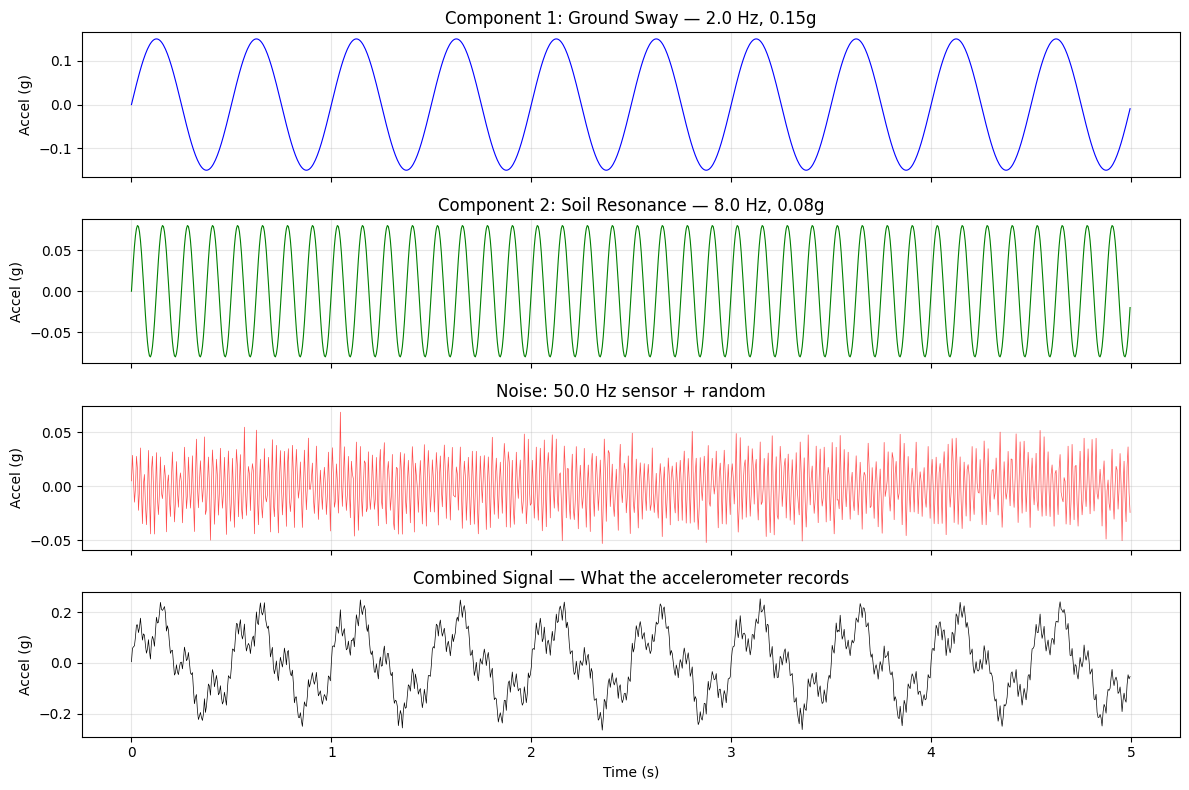

The combined signal looks messy — but the FFT will reveal its components.


In [3]:
# ─────────────────────────────────────────────────────
# PLOT THE SIGNALS — Individual and combined
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

axes[0].plot(t, signal_1, 'b-', linewidth=0.8)
axes[0].set_ylabel('Accel (g)')
axes[0].set_title(f'Component 1: Ground Sway — {f1} Hz, {A1}g')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, signal_2, 'g-', linewidth=0.8)
axes[1].set_ylabel('Accel (g)')
axes[1].set_title(f'Component 2: Soil Resonance — {f2} Hz, {A2}g')
axes[1].grid(True, alpha=0.3)

axes[2].plot(t, noise + random_noise, 'r-', linewidth=0.5, alpha=0.7)
axes[2].set_ylabel('Accel (g)')
axes[2].set_title(f'Noise: {f3} Hz sensor + random')
axes[2].grid(True, alpha=0.3)

axes[3].plot(t, accel, 'k-', linewidth=0.5)
axes[3].set_ylabel('Accel (g)')
axes[3].set_xlabel('Time (s)')
axes[3].set_title('Combined Signal — What the accelerometer records')
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("The combined signal looks messy — but the FFT will reveal its components.")

---

## Part 2: np.fft.fft — Frequency Content of Ground Motion

The **Fast Fourier Transform (FFT)** converts a time-domain signal into the **frequency domain**. It answers: *What frequencies are present, and how strong are they?*

```
Time domain:      amplitude vs time     (what the sensor records)
Frequency domain: amplitude vs frequency (what frequencies are present)
```

This is essential for:
- Identifying dominant frequencies of earthquake shaking
- Checking if site resonance matches building resonance (dangerous!)
- Separating real ground motion from sensor noise

In [4]:
# ─────────────────────────────────────────────────────
# COMPUTE THE FFT — Reveal the hidden frequencies
# ─────────────────────────────────────────────────────

# Compute FFT
fft_result = np.fft.fft(accel)

# Frequency axis
freqs = np.fft.fftfreq(N, d=dt)

# We only need the positive half (FFT is symmetric for real signals)
positive_mask = freqs >= 0
freqs_pos = freqs[positive_mask]
fft_pos = fft_result[positive_mask]

# Amplitude spectrum (magnitude of complex FFT values)
amplitude = 2 * np.abs(fft_pos) / N   # Normalize by number of samples

print(f"FFT output shape:    {fft_result.shape}")
print(f"FFT is complex:      {fft_result.dtype}")
print(f"Frequency range:     0 to {freqs_pos[-1]:.1f} Hz")
print(f"Frequency resolution: {freqs_pos[1] - freqs_pos[0]:.2f} Hz")

# Find peaks — the dominant frequencies
peak_indices = np.argsort(amplitude)[-5:][::-1]  # Top 5 by amplitude
print(f"\nDominant frequencies detected:")
for idx in peak_indices:
    if amplitude[idx] > 0.005:  # Only significant peaks
        print(f"  {freqs_pos[idx]:6.1f} Hz — amplitude {amplitude[idx]:.4f} g")

FFT output shape:    (1000,)
FFT is complex:      complex128
Frequency range:     0 to 99.8 Hz
Frequency resolution: 0.20 Hz

Dominant frequencies detected:
     2.0 Hz — amplitude 0.1495 g
     8.0 Hz — amplitude 0.0801 g
    50.0 Hz — amplitude 0.0298 g


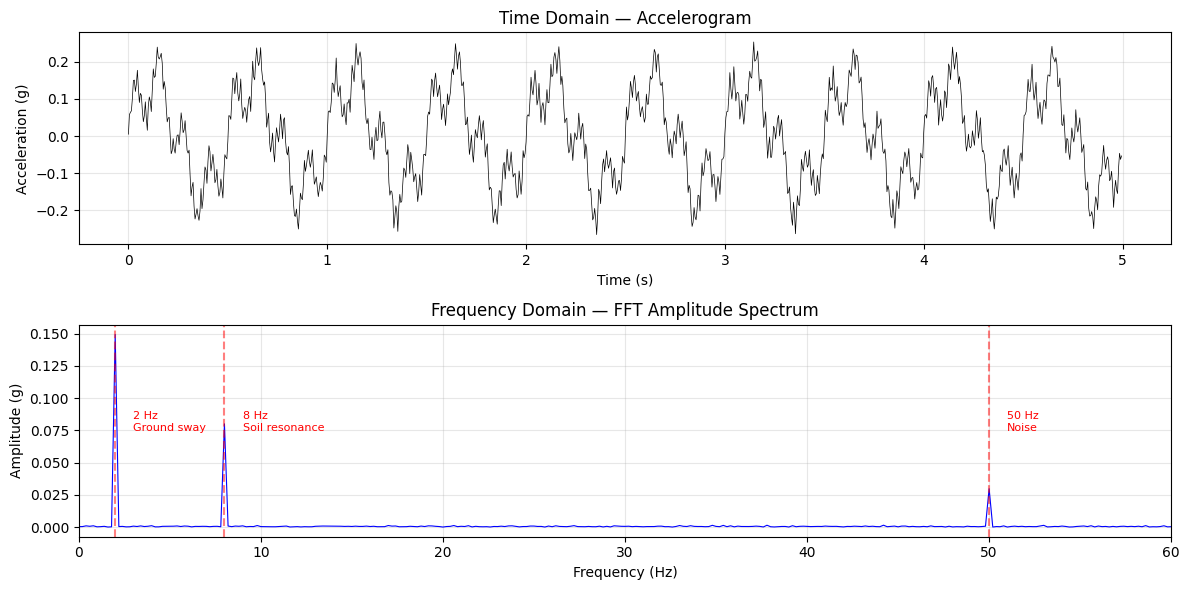

The FFT reveals exactly the frequencies we put in!
In real data, you would DISCOVER unknown frequencies this way.


In [5]:
# ─────────────────────────────────────────────────────
# PLOT THE FREQUENCY SPECTRUM
# ─────────────────────────────────────────────────────

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))

# Time domain
ax1.plot(t, accel, 'k-', linewidth=0.5)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Acceleration (g)')
ax1.set_title('Time Domain — Accelerogram')
ax1.grid(True, alpha=0.3)

# Frequency domain
ax2.plot(freqs_pos, amplitude, 'b-', linewidth=0.8)
ax2.set_xlabel('Frequency (Hz)')
ax2.set_ylabel('Amplitude (g)')
ax2.set_title('Frequency Domain — FFT Amplitude Spectrum')
ax2.set_xlim(0, 60)
ax2.grid(True, alpha=0.3)

# Mark the known frequencies
for f, label in [(2.0, '2 Hz\nGround sway'), (8.0, '8 Hz\nSoil resonance'), (50.0, '50 Hz\nNoise')]:
    ax2.axvline(f, color='r', linestyle='--', alpha=0.5)
    ax2.annotate(label, xy=(f, 0), xytext=(f+1, max(amplitude)*0.5),
                fontsize=8, color='r')

plt.tight_layout()
plt.show()

print("The FFT reveals exactly the frequencies we put in!")
print("In real data, you would DISCOVER unknown frequencies this way.")

---

## Part 3: Sampling Theorem and Nyquist Frequency

The **Nyquist-Shannon sampling theorem** is fundamental:

> To capture a frequency $f$, you must sample at **at least** $2f$ Hz.

The **Nyquist frequency** = $f_s / 2$ = the highest frequency you can faithfully represent.

| Accelerometer Rate | Nyquist Frequency | Can Capture |
|-------------------|-------------------|-------------|
| 100 Hz | 50 Hz | Most earthquake content |
| 200 Hz | 100 Hz | Vibration monitoring |
| 1000 Hz | 500 Hz | Blast/impact signals |
| 50 Hz | 25 Hz | Misses high-frequency shaking! |

**Aliasing** occurs when you sample too slowly — high frequencies disguise themselves as low frequencies. This is dangerous in earthquake engineering!

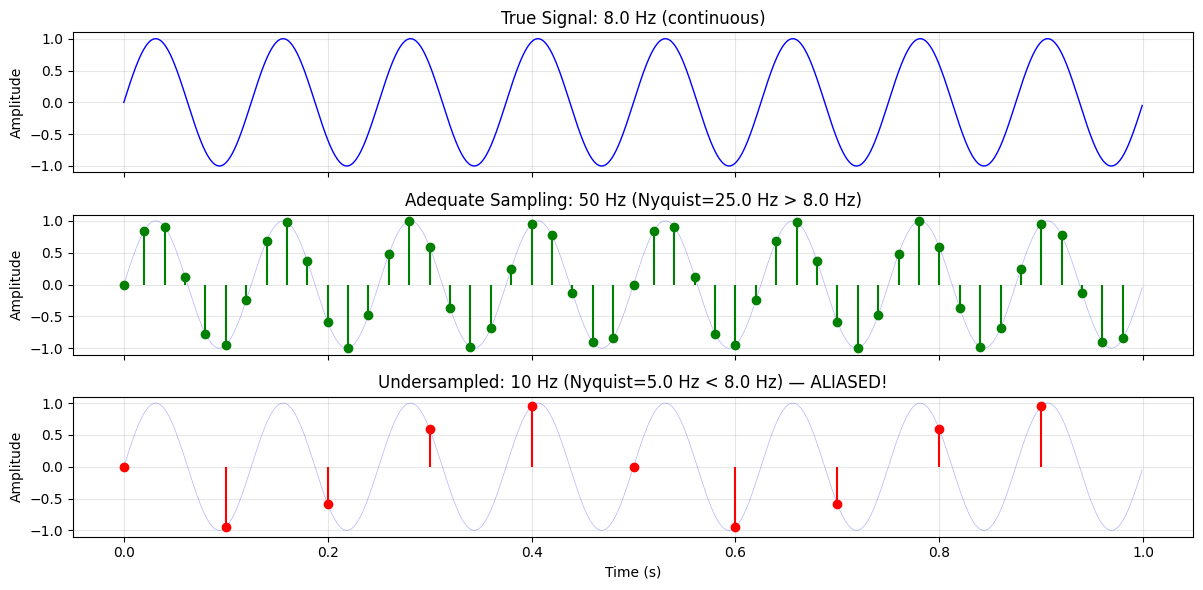

Our accelerometer: fs=200 Hz → Nyquist = 100.0 Hz
Can faithfully capture frequencies up to 100.0 Hz.
Our 50 Hz noise is RIGHT at the Nyquist limit — borderline!


In [6]:
# ─────────────────────────────────────────────────────
# DEMONSTRATE NYQUIST AND ALIASING
# ─────────────────────────────────────────────────────

# Original signal: 8 Hz sine wave
f_true = 8.0
t_fine = np.arange(0, 1.0, 0.001)   # Very fine sampling (1000 Hz)
signal_true = np.sin(2 * np.pi * f_true * t_fine)

# Adequate sampling: 50 Hz (Nyquist = 25 Hz > 8 Hz — OK)
fs_good = 50
t_good = np.arange(0, 1.0, 1/fs_good)
signal_good = np.sin(2 * np.pi * f_true * t_good)

# Undersampling: 10 Hz (Nyquist = 5 Hz < 8 Hz — ALIASED!)
fs_bad = 10
t_bad = np.arange(0, 1.0, 1/fs_bad)
signal_bad = np.sin(2 * np.pi * f_true * t_bad)

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)

axes[0].plot(t_fine, signal_true, 'b-', linewidth=1)
axes[0].set_title(f'True Signal: {f_true} Hz (continuous)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t_fine, signal_true, 'b-', linewidth=0.5, alpha=0.3)
axes[1].stem(t_good, signal_good, linefmt='g-', markerfmt='go', basefmt=' ')
axes[1].set_title(f'Adequate Sampling: {fs_good} Hz (Nyquist={fs_good/2} Hz > {f_true} Hz)')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True, alpha=0.3)

axes[2].plot(t_fine, signal_true, 'b-', linewidth=0.5, alpha=0.3)
axes[2].stem(t_bad, signal_bad, linefmt='r-', markerfmt='ro', basefmt=' ')
axes[2].set_title(f'Undersampled: {fs_bad} Hz (Nyquist={fs_bad/2} Hz < {f_true} Hz) — ALIASED!')
axes[2].set_ylabel('Amplitude')
axes[2].set_xlabel('Time (s)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Our accelerometer: fs={fs} Hz → Nyquist = {fs/2} Hz")
print(f"Can faithfully capture frequencies up to {fs/2} Hz.")
print(f"Our 50 Hz noise is RIGHT at the Nyquist limit — borderline!")

---

## Part 4: Simple FFT Filtering — Remove Noise from Acceleration Data

Now the powerful part: we can **filter** signals using the FFT.

The idea is simple:
1. Transform to frequency domain (FFT)
2. Zero out unwanted frequencies
3. Transform back to time domain (inverse FFT)

```
Noisy signal → FFT → [kill noise frequencies] → IFFT → Clean signal
```

This is a **low-pass filter** when we remove high frequencies (keep only low).

In [7]:
# ─────────────────────────────────────────────────────
# FFT LOW-PASS FILTER — Remove high-frequency noise
# ─────────────────────────────────────────────────────

# Goal: Keep ground motion (2 Hz, 8 Hz), remove noise (50 Hz)
cutoff_freq = 20.0  # Hz — keep everything below 20 Hz

# Step 1: FFT
fft_full = np.fft.fft(accel)
freqs_full = np.fft.fftfreq(N, d=dt)

# Step 2: Create filter mask — keep low, kill high
filter_mask = np.abs(freqs_full) <= cutoff_freq

# Step 3: Apply filter (zero out high frequencies)
fft_filtered = fft_full.copy()
fft_filtered[~filter_mask] = 0

# Step 4: Inverse FFT — back to time domain
accel_filtered = np.fft.ifft(fft_filtered).real

print(f"Filter: keep frequencies below {cutoff_freq} Hz")
print(f"Frequencies zeroed out: {np.sum(~filter_mask)} of {N}")
print(f"\nBefore filtering: peak = {np.max(np.abs(accel)):.4f} g")
print(f"After filtering:  peak = {np.max(np.abs(accel_filtered)):.4f} g")

# Compare: the ideal signal (no noise)
ideal = signal_1 + signal_2
error = np.sqrt(np.mean((accel_filtered - ideal)**2))
print(f"\nRMS error vs ideal: {error:.5f} g")
print("The filter recovered the true ground motion!")

Filter: keep frequencies below 20.0 Hz
Frequencies zeroed out: 799 of 1000

Before filtering: peak = 0.2659 g
After filtering:  peak = 0.2266 g

RMS error vs ideal: 0.00435 g
The filter recovered the true ground motion!


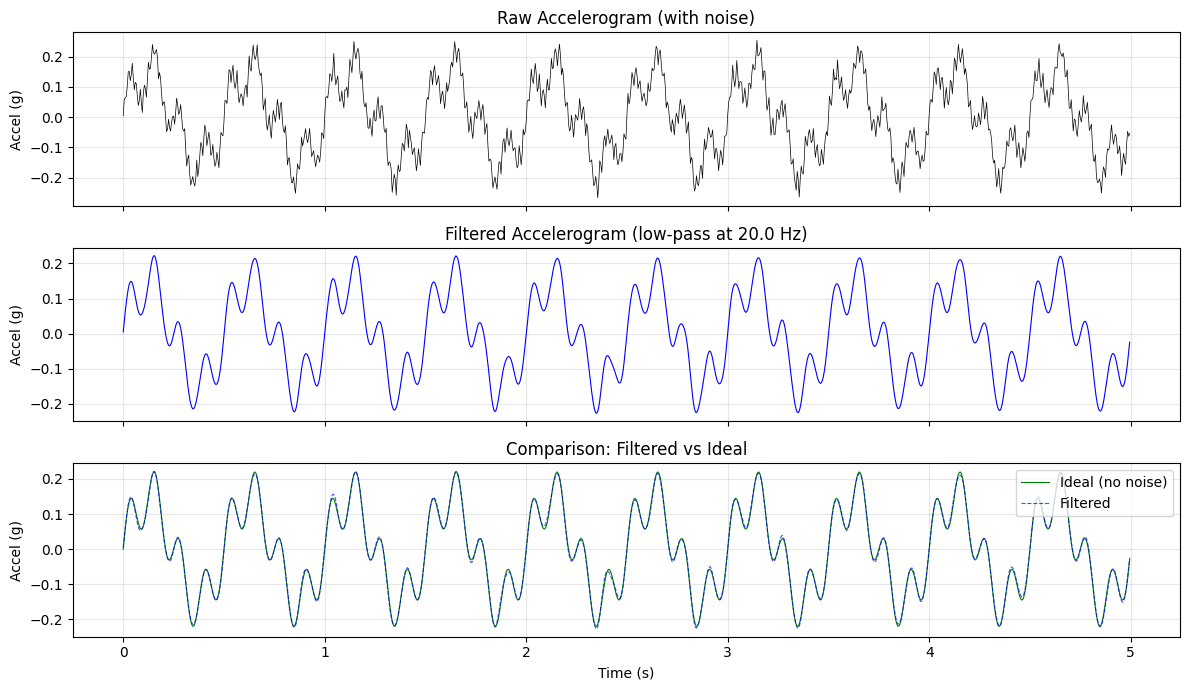

The 50 Hz noise is gone. The 2 Hz and 8 Hz ground motion is preserved.


In [8]:
# ─────────────────────────────────────────────────────
# PLOT: Before and After filtering
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)

axes[0].plot(t, accel, 'k-', linewidth=0.5)
axes[0].set_ylabel('Accel (g)')
axes[0].set_title('Raw Accelerogram (with noise)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(t, accel_filtered, 'b-', linewidth=0.8)
axes[1].set_ylabel('Accel (g)')
axes[1].set_title(f'Filtered Accelerogram (low-pass at {cutoff_freq} Hz)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(t, ideal, 'g-', linewidth=0.8, label='Ideal (no noise)')
axes[2].plot(t, accel_filtered, 'b--', linewidth=0.8, alpha=0.7, label='Filtered')
axes[2].set_ylabel('Accel (g)')
axes[2].set_xlabel('Time (s)')
axes[2].set_title('Comparison: Filtered vs Ideal')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("The 50 Hz noise is gone. The 2 Hz and 8 Hz ground motion is preserved.")

---

## Part 5: Convolution Basics — Smoothing Noisy Sensor Data

`np.convolve` slides a **kernel** (small array) across a signal, computing a weighted sum at each position. The most common use: **smoothing** noisy data.

```
Moving average kernel (size 5): [0.2, 0.2, 0.2, 0.2, 0.2]

Noisy signal:   [3, 5, 2, 8, 4, 7, 1, 6, ...]
                  ─────────
                  avg = 4.4
                    ─────────
                    avg = 5.2
```

In geotechnical monitoring, this removes spikes from piezometer or settlement gauge data.

In [9]:
# ─────────────────────────────────────────────────────
# CONVOLUTION — Smoothing noisy piezometer data
# ─────────────────────────────────────────────────────

# Simulate noisy piezometer readings over 24 hours
hours = np.linspace(0, 24, 480)  # Reading every 3 minutes

# True pore-water pressure: tidal fluctuation + consolidation trend
pwp_true = 150 + 5 * np.sin(2 * np.pi * hours / 12.4)  # Tidal period ~12.4 hrs
pwp_true += -0.5 * hours  # Slow dissipation (consolidation)

# Add sensor noise
pwp_noisy = pwp_true + 2.0 * np.random.randn(len(hours))

# Moving average kernel (size 11 = ~33 minutes of smoothing)
kernel_size = 11
kernel = np.ones(kernel_size) / kernel_size
print(f"Moving average kernel (size {kernel_size}):")
print(f"  {kernel}")
print(f"  Sum = {np.sum(kernel):.1f} (weights sum to 1)")

# Apply convolution
pwp_smooth = np.convolve(pwp_noisy, kernel, mode='same')

print(f"\nOriginal noise std:  {np.std(pwp_noisy - pwp_true):.2f} kPa")
print(f"After smoothing std: {np.std(pwp_smooth - pwp_true):.2f} kPa")
print(f"Noise reduction:     {(1 - np.std(pwp_smooth - pwp_true)/np.std(pwp_noisy - pwp_true))*100:.0f}%")

Moving average kernel (size 11):
  [0.09090909 0.09090909 0.09090909 0.09090909 0.09090909 0.09090909
 0.09090909 0.09090909 0.09090909 0.09090909 0.09090909]
  Sum = 1.0 (weights sum to 1)

Original noise std:  1.99 kPa
After smoothing std: 6.20 kPa
Noise reduction:     -211%


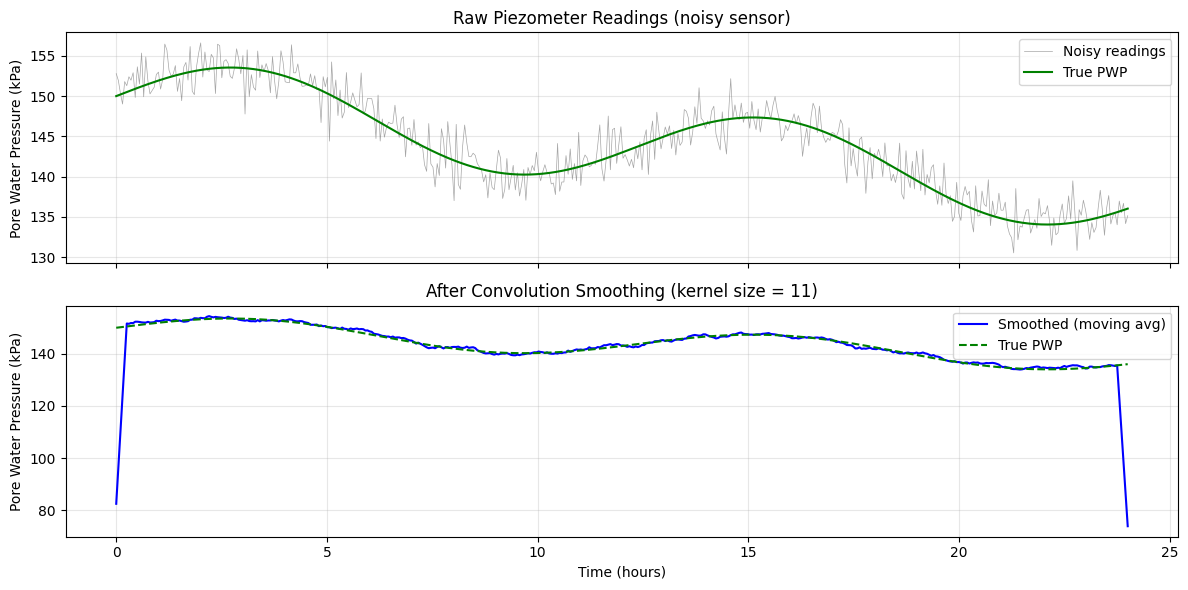

Convolution smoothing preserves the tidal pattern while removing noise.
Larger kernel = more smoothing, but also more lag.


In [10]:
# ─────────────────────────────────────────────────────
# PLOT: Noisy vs smoothed piezometer data
# ─────────────────────────────────────────────────────

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

ax1.plot(hours, pwp_noisy, 'gray', linewidth=0.5, alpha=0.7, label='Noisy readings')
ax1.plot(hours, pwp_true, 'g-', linewidth=1.5, label='True PWP')
ax1.set_ylabel('Pore Water Pressure (kPa)')
ax1.set_title('Raw Piezometer Readings (noisy sensor)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(hours, pwp_smooth, 'b-', linewidth=1.5, label='Smoothed (moving avg)')
ax2.plot(hours, pwp_true, 'g--', linewidth=1.5, label='True PWP')
ax2.set_ylabel('Pore Water Pressure (kPa)')
ax2.set_xlabel('Time (hours)')
ax2.set_title(f'After Convolution Smoothing (kernel size = {kernel_size})')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Convolution smoothing preserves the tidal pattern while removing noise.")
print("Larger kernel = more smoothing, but also more lag.")

---

## Part 6: Window Functions for Spectral Analysis

When we compute the FFT of a finite signal, the signal edges create **spectral leakage** — fake frequency content that isn't really there.

**Window functions** taper the signal to zero at the edges, reducing leakage:

| Window | Shape | Use Case |
|--------|-------|----------|
| Rectangular | Flat (no taper) | Default — most leakage |
| Hanning | Smooth bell | General-purpose spectral analysis |
| Hamming | Similar, nonzero edges | Speech/vibration processing |
| Blackman | Wider bell | Best side-lobe suppression |

In geotechnical vibration monitoring, windowing is critical for identifying true resonant frequencies from blast or pile-driving records.

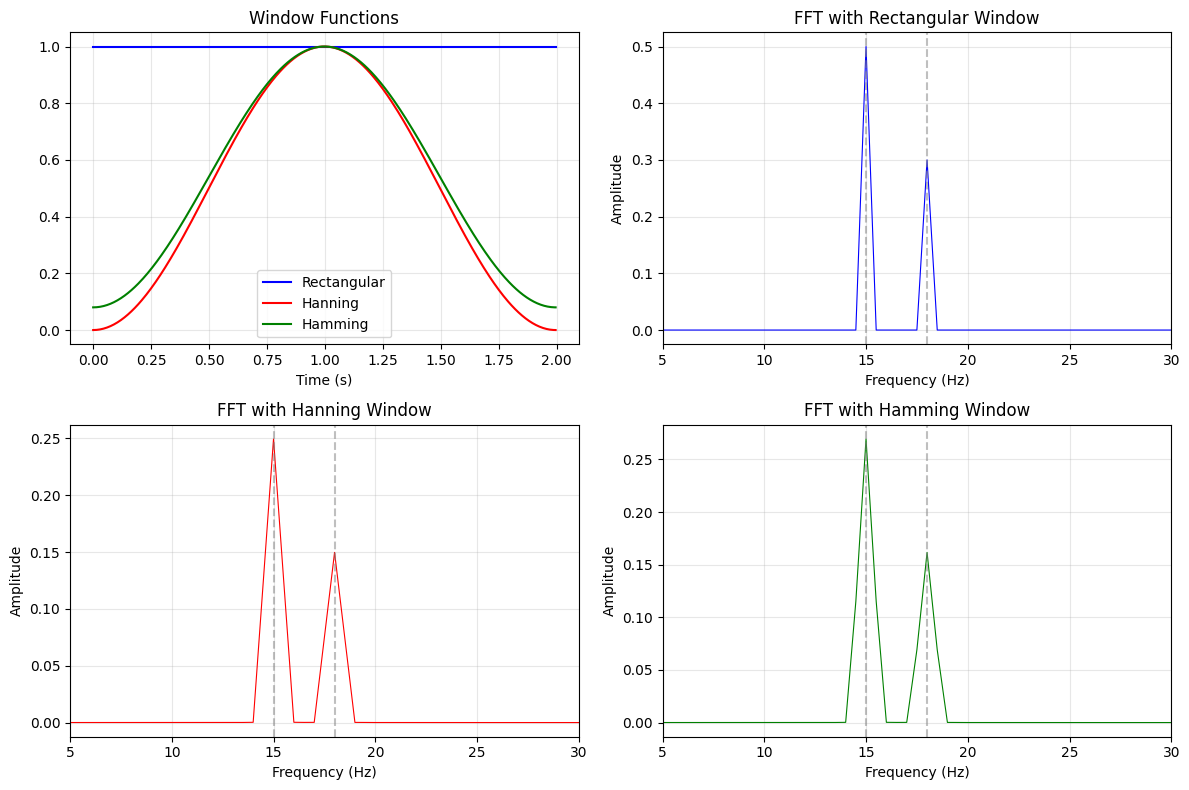

Hanning/Hamming windows produce cleaner peaks with less spectral leakage.
The two peaks at 15 Hz and 18 Hz are more clearly separated.


In [11]:
# ─────────────────────────────────────────────────────
# WINDOW FUNCTIONS — Compare effects on spectral analysis
# ─────────────────────────────────────────────────────

# Generate a blast vibration signal: two close frequencies
t_blast = np.arange(0, 2.0, 1/200)  # 2 seconds at 200 Hz
N_blast = len(t_blast)

# Two close frequencies: 15 Hz and 18 Hz (pile-driving harmonics)
blast_signal = 0.5 * np.sin(2 * np.pi * 15 * t_blast) + \
               0.3 * np.sin(2 * np.pi * 18 * t_blast)

# Create windows
win_rect = np.ones(N_blast)                  # Rectangular (no window)
win_hann = np.hanning(N_blast)                # Hanning
win_hamm = np.hamming(N_blast)                # Hamming

# Compute FFT with each window
freqs_blast = np.fft.fftfreq(N_blast, d=1/200)
pos_mask = freqs_blast >= 0

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot windows
axes[0, 0].plot(t_blast, win_rect, 'b-', label='Rectangular')
axes[0, 0].plot(t_blast, win_hann, 'r-', label='Hanning')
axes[0, 0].plot(t_blast, win_hamm, 'g-', label='Hamming')
axes[0, 0].set_title('Window Functions')
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# FFT with each window
windows = [('Rectangular', win_rect, 'b'), ('Hanning', win_hann, 'r'), ('Hamming', win_hamm, 'g')]
for i, (name, win, color) in enumerate(windows):
    windowed = blast_signal * win
    fft_w = np.fft.fft(windowed)
    amp_w = 2 * np.abs(fft_w[pos_mask]) / N_blast
    
    ax = axes[0, 1] if i == 0 else axes[1, i-1]
    ax.plot(freqs_blast[pos_mask], amp_w, color=color, linewidth=0.8)
    ax.set_xlim(5, 30)
    ax.set_title(f'FFT with {name} Window')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude')
    ax.axvline(15, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(18, color='gray', linestyle='--', alpha=0.5)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Hanning/Hamming windows produce cleaner peaks with less spectral leakage.")
print("The two peaks at 15 Hz and 18 Hz are more clearly separated.")

---

## Part 7: Complete Application — Earthquake Accelerogram Analysis

Let's put it all together: generate a realistic synthetic earthquake, analyze its frequency content, identify the dominant frequency, and filter out high-frequency noise.

A simplified earthquake model:
- **Envelope function**: amplitude builds up, peaks, then decays (like a real earthquake)
- **Multiple frequency components**: low (structural), mid (soil), high (noise)
- **Random phase**: each frequency component has a random starting phase

In [12]:
# ═══════════════════════════════════════════════════════
# COMPLETE APPLICATION: Earthquake Record Analysis
# ═══════════════════════════════════════════════════════

# --- Step 1: Generate synthetic earthquake ---
fs_eq = 200            # 200 Hz sampling rate
dt_eq = 1 / fs_eq
duration_eq = 20.0     # 20-second earthquake
t_eq = np.arange(0, duration_eq, dt_eq)
N_eq = len(t_eq)

# Envelope: ramp up (2s), sustain (8s), decay (10s)
envelope = np.zeros(N_eq)
t_ramp = 2.0
t_sustain = 10.0
for i, ti in enumerate(t_eq):
    if ti < t_ramp:
        envelope[i] = ti / t_ramp                          # Ramp up
    elif ti < t_sustain:
        envelope[i] = 1.0                                  # Sustain
    else:
        envelope[i] = np.exp(-0.3 * (ti - t_sustain))     # Exponential decay

# Multiple frequency components with random phases
np.random.seed(42)
eq_freqs = [0.8, 1.5, 3.0, 5.0, 8.0, 12.0]   # Hz
eq_amps  = [0.02, 0.08, 0.15, 0.10, 0.05, 0.03]  # g
phases   = np.random.uniform(0, 2*np.pi, len(eq_freqs))

eq_signal = np.zeros(N_eq)
for f, A, phi in zip(eq_freqs, eq_amps, phases):
    eq_signal += A * np.sin(2 * np.pi * f * t_eq + phi)

# Apply envelope
eq_signal *= envelope

# Add realistic noise
high_freq_noise = 0.02 * np.sin(2 * np.pi * 55 * t_eq)  # Electrical noise
random_noise_eq = 0.005 * np.random.randn(N_eq)
eq_noisy = eq_signal + high_freq_noise + random_noise_eq

PGA = np.max(np.abs(eq_noisy))
print(f"Synthetic earthquake generated:")
print(f"  Duration:     {duration_eq} s")
print(f"  Sampling:     {fs_eq} Hz")
print(f"  PGA:          {PGA:.3f} g")
print(f"  Components:   {len(eq_freqs)} frequencies")
print(f"  Frequencies:  {eq_freqs} Hz")

Synthetic earthquake generated:
  Duration:     20.0 s
  Sampling:     200 Hz
  PGA:          0.435 g
  Components:   6 frequencies
  Frequencies:  [0.8, 1.5, 3.0, 5.0, 8.0, 12.0] Hz


In [13]:
# ═══════════════════════════════════════════════════════
# Step 2: Compute FFT and identify dominant frequency
# ═══════════════════════════════════════════════════════

# Apply Hanning window for cleaner spectrum
window = np.hanning(N_eq)
eq_windowed = eq_noisy * window

# FFT
fft_eq = np.fft.fft(eq_windowed)
freqs_eq = np.fft.fftfreq(N_eq, d=dt_eq)
pos_eq = freqs_eq >= 0
amp_eq = 2 * np.abs(fft_eq[pos_eq]) / N_eq
freqs_eq_pos = freqs_eq[pos_eq]

# Find dominant frequency
dominant_idx = np.argmax(amp_eq)
f_dominant = freqs_eq_pos[dominant_idx]
a_dominant = amp_eq[dominant_idx]

# Find all significant peaks (above 20% of max)
threshold = 0.2 * a_dominant
significant = amp_eq > threshold

print(f"Dominant frequency: {f_dominant:.1f} Hz (amplitude: {a_dominant:.4f} g)")
print(f"\nAll significant frequency peaks:")

# Simple peak finding: check if point is higher than neighbors
for i in range(1, len(amp_eq)-1):
    if amp_eq[i] > threshold and amp_eq[i] > amp_eq[i-1] and amp_eq[i] > amp_eq[i+1]:
        if freqs_eq_pos[i] < 70:  # Only up to 70 Hz
            print(f"  {freqs_eq_pos[i]:6.1f} Hz — {amp_eq[i]:.4f} g")

Dominant frequency: 3.0 Hz (amplitude: 0.0556 g)

All significant frequency peaks:
     1.5 Hz — 0.0297 g
     3.0 Hz — 0.0556 g
     5.0 Hz — 0.0369 g
     8.0 Hz — 0.0185 g
    12.0 Hz — 0.0112 g


In [14]:
# ═══════════════════════════════════════════════════════
# Step 3: Filter — remove noise, keep ground motion
# ═══════════════════════════════════════════════════════

# Low-pass filter at 25 Hz (keep earthquake content, remove 55 Hz noise)
cutoff = 25.0
fft_eq_full = np.fft.fft(eq_noisy)
freqs_eq_full = np.fft.fftfreq(N_eq, d=dt_eq)

# Create smooth filter (tapered, not sharp cutoff)
filter_eq = np.ones(N_eq)
taper_width = 5.0  # Hz — gradual rolloff
for i in range(N_eq):
    f_abs = abs(freqs_eq_full[i])
    if f_abs > cutoff + taper_width:
        filter_eq[i] = 0.0
    elif f_abs > cutoff:
        filter_eq[i] = 0.5 * (1 + np.cos(np.pi * (f_abs - cutoff) / taper_width))

# Apply filter and inverse FFT
fft_eq_filtered = fft_eq_full * filter_eq
eq_clean = np.fft.ifft(fft_eq_filtered).real

print(f"Low-pass filter: cutoff = {cutoff} Hz, taper = {taper_width} Hz")
print(f"\nBefore: PGA = {np.max(np.abs(eq_noisy)):.4f} g")
print(f"After:  PGA = {np.max(np.abs(eq_clean)):.4f} g")
print(f"\nArias Intensity proxy (sum of a^2):")
print(f"  Noisy:  {np.sum(eq_noisy**2) * dt_eq:.4f}")
print(f"  Clean:  {np.sum(eq_clean**2) * dt_eq:.4f}")
print(f"  Ideal:  {np.sum(eq_signal**2) * dt_eq:.4f}")

Low-pass filter: cutoff = 25.0 Hz, taper = 5.0 Hz

Before: PGA = 0.4352 g
After:  PGA = 0.4106 g

Arias Intensity proxy (sum of a^2):
  Noisy:  0.2255
  Clean:  0.2211
  Ideal:  0.2206


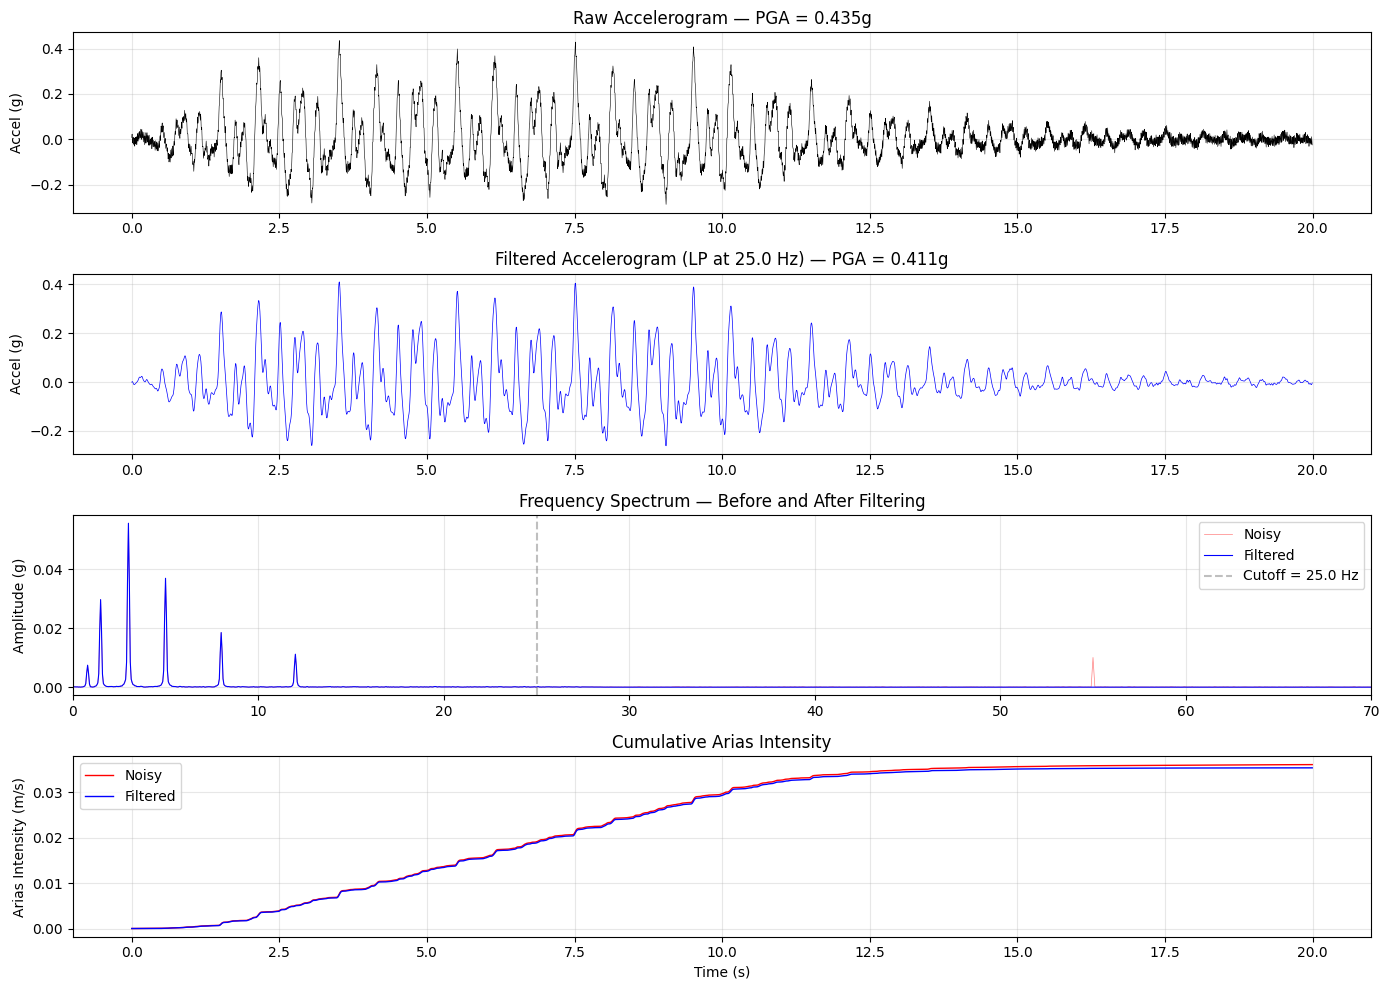


Analysis complete!
  Dominant frequency:  3.0 Hz
  PGA (filtered):     0.411 g
  55 Hz noise:        Successfully removed


In [15]:
# ═══════════════════════════════════════════════════════
# Step 4: Final visualization — complete analysis
# ═══════════════════════════════════════════════════════

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

# Raw record
axes[0].plot(t_eq, eq_noisy, 'k-', linewidth=0.4)
axes[0].set_ylabel('Accel (g)')
axes[0].set_title(f'Raw Accelerogram — PGA = {np.max(np.abs(eq_noisy)):.3f}g')
axes[0].grid(True, alpha=0.3)

# Filtered record
axes[1].plot(t_eq, eq_clean, 'b-', linewidth=0.5)
axes[1].set_ylabel('Accel (g)')
axes[1].set_title(f'Filtered Accelerogram (LP at {cutoff} Hz) — PGA = {np.max(np.abs(eq_clean)):.3f}g')
axes[1].grid(True, alpha=0.3)

# Frequency spectrum (before and after)
amp_clean = 2 * np.abs(np.fft.fft(eq_clean * window)[pos_eq]) / N_eq
axes[2].plot(freqs_eq_pos, amp_eq, 'r-', linewidth=0.5, alpha=0.5, label='Noisy')
axes[2].plot(freqs_eq_pos, amp_clean, 'b-', linewidth=0.8, label='Filtered')
axes[2].set_xlim(0, 70)
axes[2].set_ylabel('Amplitude (g)')
axes[2].set_title('Frequency Spectrum — Before and After Filtering')
axes[2].axvline(cutoff, color='gray', linestyle='--', alpha=0.5, label=f'Cutoff = {cutoff} Hz')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# Cumulative Arias Intensity
arias_noisy = np.cumsum(eq_noisy**2) * dt_eq * np.pi / (2 * 9.81)
arias_clean = np.cumsum(eq_clean**2) * dt_eq * np.pi / (2 * 9.81)
axes[3].plot(t_eq, arias_noisy, 'r-', linewidth=1, label='Noisy')
axes[3].plot(t_eq, arias_clean, 'b-', linewidth=1, label='Filtered')
axes[3].set_ylabel('Arias Intensity (m/s)')
axes[3].set_xlabel('Time (s)')
axes[3].set_title('Cumulative Arias Intensity')
axes[3].legend()
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nAnalysis complete!")
print(f"  Dominant frequency:  {f_dominant:.1f} Hz")
print(f"  PGA (filtered):     {np.max(np.abs(eq_clean)):.3f} g")
print(f"  55 Hz noise:        Successfully removed")

---

## Practice Exercises

### Exercise 1: Band-pass filter
Create a **band-pass filter** that keeps only frequencies between 2 Hz and 15 Hz. Apply it to `eq_noisy` and plot the result. This isolates the typical building-response frequency band.

### Exercise 2: Different smoothing kernels
Compare three convolution kernels on `pwp_noisy`:
- Moving average (size 21)
- Gaussian kernel: `np.exp(-0.5 * (x/sigma)**2)` with sigma=3
- Triangular kernel: `[1, 2, 3, 4, 5, 4, 3, 2, 1]` (normalized)

Which preserves the tidal pattern best while smoothing noise?

### Exercise 3: Spectral ratio
Compute the FFT of `eq_noisy` at the surface and create a synthetic "bedrock" signal (use only the 0.8 Hz and 1.5 Hz components). Compute the spectral ratio (surface / bedrock amplitude) and find the site amplification factor at each frequency.

In [16]:
# EXERCISE 1: Band-pass filter
# low_cut = 2.0    # Hz
# high_cut = 15.0  # Hz
# fft_bp = np.fft.fft(eq_noisy)
# freqs_bp = np.fft.fftfreq(N_eq, d=dt_eq)
# mask_bp = (np.abs(freqs_bp) >= low_cut) & (np.abs(freqs_bp) <= high_cut)
# fft_bp[~mask_bp] = 0
# eq_bandpass = np.fft.ifft(fft_bp).real
# plt.plot(t_eq, eq_bandpass)
# plt.title('Band-pass filtered: 2-15 Hz')
# plt.show()

In [17]:
# EXERCISE 2: Different smoothing kernels
# kernel_gauss = np.exp(-0.5 * (np.arange(-10,11)/3)**2)
# kernel_gauss /= kernel_gauss.sum()
# kernel_tri = np.array([1,2,3,4,5,4,3,2,1], dtype=float)
# kernel_tri /= kernel_tri.sum()
# ...

In [18]:
# EXERCISE 3: Spectral ratio (surface/bedrock)
# bedrock = 0.02*np.sin(2*np.pi*0.8*t_eq) + 0.08*np.sin(2*np.pi*1.5*t_eq)
# fft_surface = np.abs(np.fft.fft(eq_noisy))
# fft_bedrock = np.abs(np.fft.fft(bedrock))
# ratio = fft_surface / (fft_bedrock + 1e-10)  # avoid div by zero
# ...

---

## Key Takeaways

1. **`np.fft.fft` decomposes a signal into its frequency components.** For seismic data, this reveals dominant shaking frequencies — critical for site response analysis and structural design.

2. **The Nyquist frequency = fs/2 is your hard limit.** An accelerometer sampling at 200 Hz cannot faithfully capture anything above 100 Hz. Undersampling causes aliasing — fake low-frequency content.

3. **FFT filtering (forward FFT → zero frequencies → inverse FFT) is a powerful noise-removal tool.** Low-pass, high-pass, and band-pass filters can all be built this way.

4. **`np.convolve` with a moving-average kernel smooths noisy monitoring data.** Larger kernels = more smoothing but more lag. Gaussian kernels give smoother results than rectangular.

5. **Window functions (Hanning, Hamming) reduce spectral leakage** and give cleaner frequency peaks. Always window before FFT when analyzing finite-duration signals.

---

## How This Connects to ML

| Today | ML Equivalent |
|-------|---------------|
| FFT frequency features | Feature extraction for vibration classification |
| Dominant frequency detection | Input features for site classification models |
| Filtering noisy signals | Data preprocessing before model training |
| Convolution smoothing | 1D CNN kernels learn optimal smoothing filters |
| Window functions | Attention mechanisms focus on signal segments |
| Spectral analysis | Spectrogram inputs for deep learning (earthquake detection) |

**Signal processing is preprocessing for ML.** When you feed seismic data into a neural network, the model internally learns FFT-like operations. Understanding them manually makes you a better ML engineer.

---

*Day 018 of 100 — We can now hear the hidden frequencies in ground motion!*